# Healthcare Spending Survey: Data Analysis

In this notebook I load the survey responses (exported from MongoDB to `data/user_data.csv` by `export_to_csv.py`) and answer the two questions from the brief:

1. **Which ages have the highest income?**
2. **How are the genders spread across the spending categories?**

Every chart is also saved as a high-resolution PNG in the `charts/` folder, so it can go straight into a PowerPoint deck for the client.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

DATA_PATH = Path("data/user_data.csv")
CHARTS_DIR = Path("charts")
CHARTS_DIR.mkdir(exist_ok=True)

CATEGORIES = {
    "utilities": "Utilities",
    "entertainment": "Entertainment",
    "school_fees": "School Fees",
    "shopping": "Shopping",
    "healthcare": "Healthcare",
}

# Same order and colour for each gender in every chart.
GENDER_ORDER = ["Male", "Female", "Non-binary", "Prefer not to say"]
GENDER_COLORS = dict(zip(GENDER_ORDER, sns.color_palette("deep", len(GENDER_ORDER))))


def save_chart(fig, name):
    """Save a chart as a 300-dpi PNG for PowerPoint."""
    path = CHARTS_DIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved {path}")

## 1. Load and inspect the data

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"{len(df)} responses, {df.shape[1]} columns")
df.head()

205 responses, 9 columns


,age,gender,total_income,utilities,entertainment,school_fees,shopping,healthcare,total_expenses
0,18,Male,3502.70,340.48,453.23,496.39,194.61,327.67,1812.38
1,58,Female,5788.04,421.98,424.89,0.00,190.23,0.00,1037.10
2,64,Male,3426.82,0.00,249.16,0.00,331.98,234.42,815.56
3,70,Female,5382.23,0.00,403.61,0.00,0.00,0.00,403.61
4,31,Male,2932.70,131.64,358.60,275.00,0.00,416.79,1182.03


In [3]:
df.info()
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             205 non-null    int64  
 1   gender          205 non-null    str    
 2   total_income    205 non-null    float64
 3   utilities       205 non-null    float64
 4   entertainment   205 non-null    float64
 5   school_fees     205 non-null    float64
 6   shopping        205 non-null    float64
 7   healthcare      205 non-null    float64
 8   total_expenses  205 non-null    float64
dtypes: float64(7), int64(1), str(1)
memory usage: 14.5 KB


,age,total_income,utilities,entertainment,school_fees,shopping,healthcare,total_expenses
count,205.00,205.00,205.00,205.00,205.00,205.00,205.00,205.00
mean,44.54,4624.29,297.54,276.56,190.65,274.36,313.76,1352.86
std,15.30,1326.86,248.40,246.00,253.08,247.77,262.10,621.43
min,18.00,300.00,0.00,0.00,0.00,0.00,0.00,188.03
25%,31.00,3721.65,0.00,0.00,0.00,0.00,0.00,909.67
50%,44.00,4666.28,298.71,280.19,0.00,261.95,309.00,1279.59
75%,58.00,5615.63,466.14,463.54,385.03,449.76,475.78,1777.95
max,70.00,7169.23,1000.00,1021.40,997.53,1000.00,957.44,3739.59


## 2. Clean the data

In [4]:
# Drop incomplete rows and make sure numeric columns are numeric.
numeric_cols = ["age", "total_income", *CATEGORIES, "total_expenses"]
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")
df = df.dropna(subset=["age", "gender", "total_income"])
df[list(CATEGORIES)] = df[list(CATEGORIES)].fillna(0)
df["age"] = df["age"].astype(int)

# Age bands make the trend easier to read for a client audience.
bins = [17, 24, 34, 44, 54, 64, 120]
labels = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels)

print(f"{len(df)} rows after cleaning")
df.gender.value_counts()

205 rows after cleaning


gender
Male                 99
Female               91
Non-binary           10
Prefer not to say     5
Name: count, dtype: int64

## 3. Ages with the highest income

I look at this two ways. First, the 10 individual ages with the highest **average** income. Then, because some ages only have one or two people, average income by age group, which shows the overall trend more reliably.

In [5]:
income_by_age = (
    df.groupby("age")["total_income"]
      .agg(average_income="mean", respondents="count")
      .sort_values("average_income", ascending=False)
)
top_ages = income_by_age.head(10)
top_ages.round(2)

,average_income,respondents
age,,
37,7055.86,2
55,6159.06,2
65,5849.17,1
54,5811.53,7
41,5749.49,3
66,5724.32,3
62,5711.35,6
60,5628.11,3
58,5628.01,6


Saved charts\01_top_ages_by_income.png


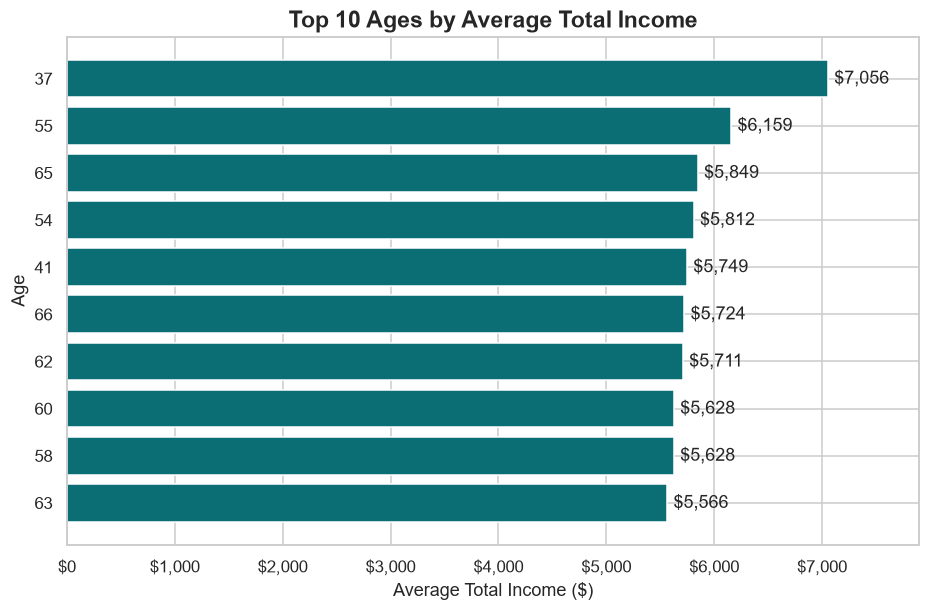

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_data = top_ages.reset_index().sort_values("average_income")
bars = ax.barh(plot_data["age"].astype(str), plot_data["average_income"], color="#0b6e75")
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in plot_data["average_income"]], padding=4)
ax.set_title("Top 10 Ages by Average Total Income", fontsize=15, weight="bold")
ax.set_xlabel("Average Total Income ($)")
ax.set_ylabel("Age")
ax.xaxis.set_major_formatter(lambda x, _: f"${x:,.0f}")
ax.margins(x=0.12)
save_chart(fig, "01_top_ages_by_income.png")
plt.show()

Saved charts\02_income_by_age_group.png


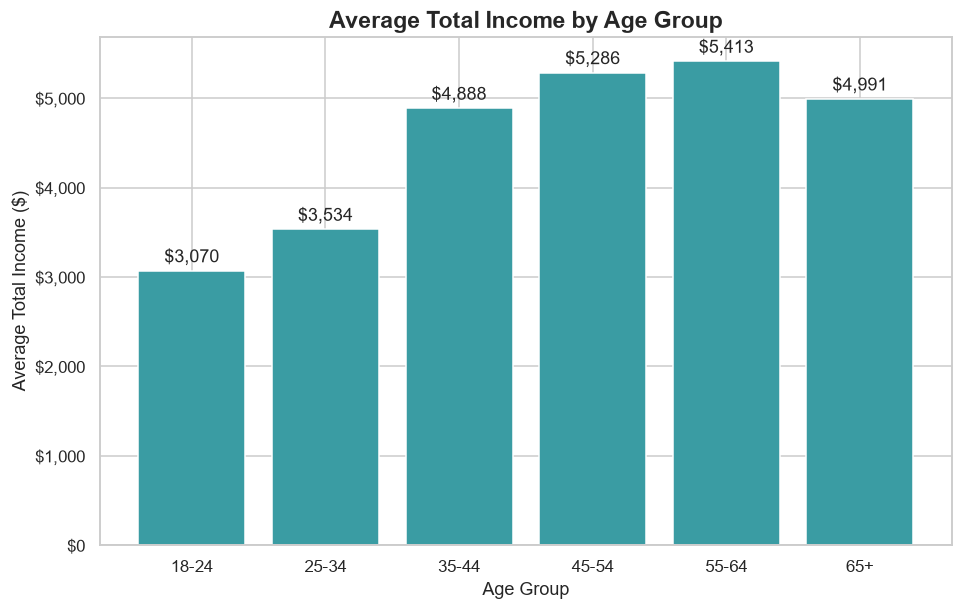

In [7]:
income_by_group = df.groupby("age_group", observed=True)["total_income"].mean()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(income_by_group.index.astype(str), income_by_group.values, color="#3a9ca3")
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in income_by_group.values], padding=3)
ax.set_title("Average Total Income by Age Group", fontsize=15, weight="bold")
ax.set_xlabel("Age Group")
ax.set_ylabel("Average Total Income ($)")
ax.yaxis.set_major_formatter(lambda y, _: f"${y:,.0f}")
save_chart(fig, "02_income_by_age_group.png")
plt.show()

## 4. Gender distribution across spending categories

The five expense columns are reshaped into one long table (one row per person per category), which makes it easy to group by both category and gender. Two charts come out of it:
- how much **money** each gender spent in each category, and
- how many **people** of each gender spent anything in each category.

In [8]:
spending = df.melt(
    id_vars=["gender"],
    value_vars=list(CATEGORIES),
    var_name="category",
    value_name="amount",
)
spending["category"] = spending["category"].map(CATEGORIES)

total_by_gender = spending.pivot_table(index="category", columns="gender", values="amount", aggfunc="sum")
total_by_gender.round(2)

gender,Female,Male,Non-binary,Prefer not to say
category,,,,
Entertainment,25947.67,27260.22,2093.86,1392.73
Healthcare,24714.19,33777.20,4003.09,1825.70
School Fees,19234.27,16757.91,2677.16,413.25
Shopping,26489.39,25043.81,3379.15,1331.63
Utilities,27368.59,27827.97,4163.60,1635.27


Saved charts\03_spending_by_category_and_gender.png


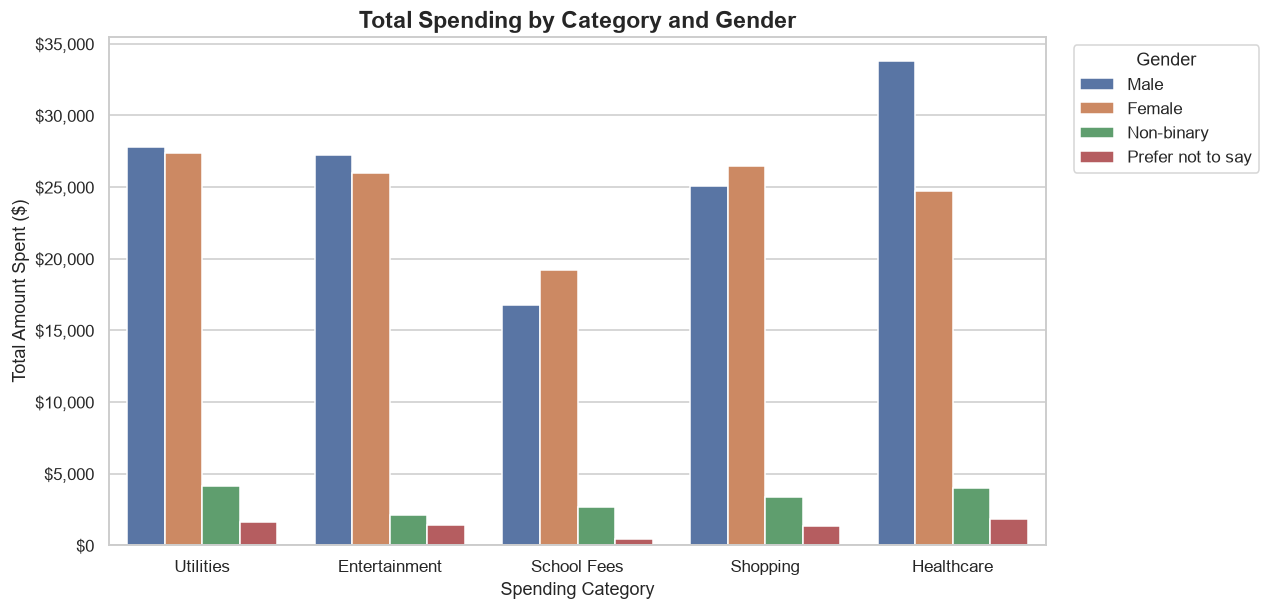

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=spending, x="category", y="amount", hue="gender", hue_order=GENDER_ORDER,
            palette=GENDER_COLORS, estimator="sum", errorbar=None, ax=ax)
ax.set_title("Total Spending by Category and Gender", fontsize=15, weight="bold")
ax.set_xlabel("Spending Category")
ax.set_ylabel("Total Amount Spent ($)")
ax.yaxis.set_major_formatter(lambda y, _: f"${y:,.0f}")
ax.legend(title="Gender", bbox_to_anchor=(1.02, 1), loc="upper left")
save_chart(fig, "03_spending_by_category_and_gender.png")
plt.show()

Saved charts\04_participants_by_category_and_gender.png


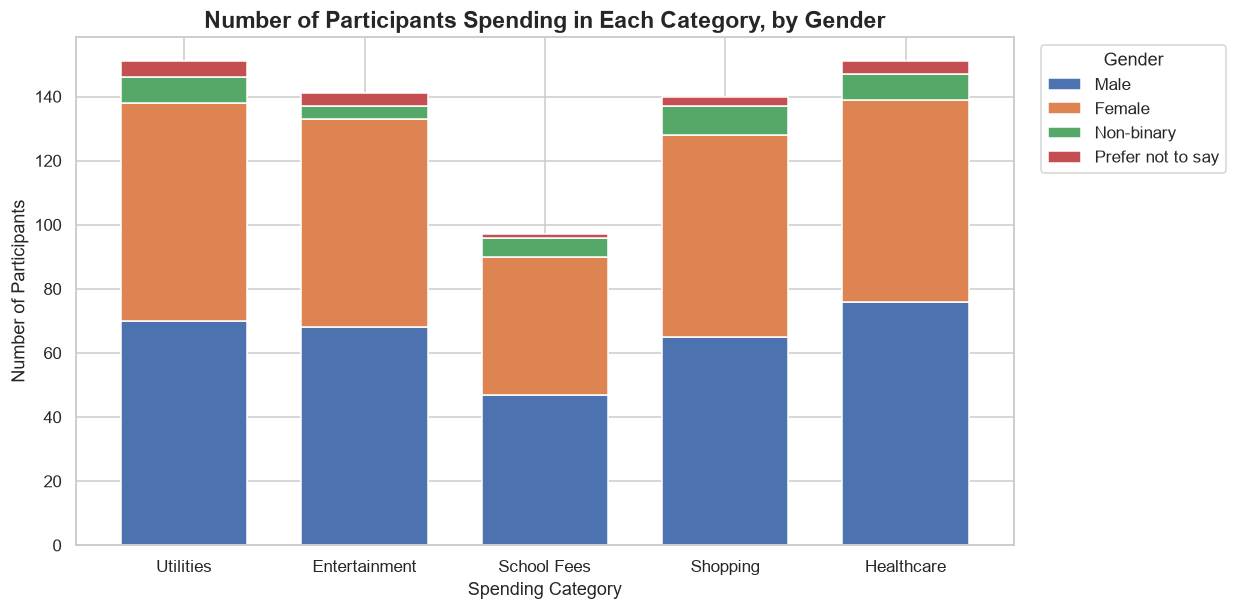

gender,Male,Female,Non-binary,Prefer not to say
category,,,,
Utilities,70,68,8,5
Entertainment,68,65,4,4
School Fees,47,43,6,1
Shopping,65,63,9,3
Healthcare,76,63,8,4


In [10]:
spenders = spending[spending["amount"] > 0]
counts = (
    spenders.groupby(["category", "gender"]).size().unstack(fill_value=0)
    .reindex(index=list(CATEGORIES.values()), columns=GENDER_ORDER, fill_value=0)
)

fig, ax = plt.subplots(figsize=(11, 6))
counts.plot(kind="bar", stacked=True, ax=ax, color=[GENDER_COLORS[g] for g in counts.columns], width=0.7)
ax.set_title("Number of Participants Spending in Each Category, by Gender", fontsize=15, weight="bold")
ax.set_xlabel("Spending Category")
ax.set_ylabel("Number of Participants")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Gender", bbox_to_anchor=(1.02, 1), loc="upper left")
save_chart(fig, "04_participants_by_category_and_gender.png")
plt.show()
counts

## 5. Summary

### What the data shows (205 responses)

**Income and age**
- Income climbs steadily with age, from about **\$3,070** for 18–24 year-olds to a peak of about **\$5,410** for the **55–64** group. It then drops a little, to about \$4,990, for people over 65.
- On its own, age **37** has the highest average income (about \$7,060). But each single age has only between 1 and 7 people in it, so I'd trust the age-group chart more than this one.

**Spending by category and gender**
- **Healthcare is where the most money goes**: about \$64,300 in total. 151 of the 205 people (74%) spend something on it, the same as utilities.
- **Men spend more on healthcare than women**: about \$341 a person against \$272 (averaged over everyone, including people who spend nothing on it).
- Women spend a little more per person on shopping (\$291 vs \$253) and on school fees (\$211 vs \$169).
- **School fees are the least common expense.** Only 97 people pay them.
- The Non-binary (10 people) and "Prefer not to say" (5 people) groups are too small to read much into.
- Altogether, these five categories take up about **29% of people's income**.

**What this means for the product launch:** almost everyone already spends money on healthcare, and it's the biggest single expense. The 35–64 age range, where incomes are highest, and men, who spend the most on healthcare, look like the best groups to target first.

> One caveat: 200 of the 205 responses are test data generated by `seed_data.py`. The numbers show that the analysis works end to end, but they don't describe real people.

### Charts for PowerPoint

All four charts are in the `charts/` folder (in PowerPoint: **Insert → Pictures → This Device**):

| File | What it shows |
|---|---|
| `01_top_ages_by_income.png` | The 10 ages with the highest average income |
| `02_income_by_age_group.png` | How average income changes across age groups |
| `03_spending_by_category_and_gender.png` | Total money spent in each category, split by gender |
| `04_participants_by_category_and_gender.png` | How many people of each gender spend in each category |